# Assignment 4: Double ML and Meta-Learners (Group 10)

**Dataset:** Student Stress Monitoring (Kaggle), 1,100 students × 21 variables.
**Outcome:** `stress_level` (0 = low, 1 = medium, 2 = high).
**Causes:** `study_load`, `noise_level`, `living_conditions`, `academic_performance`, `future_career_concerns`.

| Part | Who | Nuisance models | What gets adjusted for |
|---|---|---|---|
| 0 | Group (A3) | none (DoWhy backdoor OLS) | DAG4 adjustment sets (0–2 vars) |
| 1 | Oliver | Linear + XGBoost, DML written by hand | 8 pre-treatment confounders + DAG4 sets |
| 2 | Minhae | XGBoost + SVR (EconML `LinearDML`) | DAG4 sets + safety, mental_health_history |
| 3 | Camille | MLP + LightGBM (`LinearDML`, `CausalForestDML`) + Q6 non-causal models | DAG4 nodes that aren't descendants of the cause (3–6 vars) |
| 4 | Sabayna | Random Forest + ElasticNet (`LinearDML`) | DAG4 sets + the 15 other predictors |
| 5 | Group | Comparison and answers to Q5–Q10 | |

Run top to bottom. Reads `../data/StressLevelDataset.csv` and writes to `../results/`.
Slowest cells: Minhae's scorecard and Camille's Q6 bootstrap (a few minutes each).

In [1]:
# %pip install "numpy<2.2" "pandas<3" econml==0.17.0 dowhy==0.14 lightgbm xgboost statsmodels networkx matplotlib
import os, warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import statsmodels.api as sm
from dowhy import CausalModel
warnings.filterwarnings('ignore')

os.makedirs('../results', exist_ok=True)

df = pd.read_csv('../data/StressLevelDataset.csv')
stress = df  # name used by the A3 code

CAUSES = ['study_load', 'noise_level', 'living_conditions',
          'academic_performance', 'future_career_concerns']
TREATMENTS = CAUSES  # name used by Camille's code
OUTCOME = 'stress_level'

print(df.shape)

(1100, 21)


---
# Part 0: Assignment 3 recap (Q1–Q4)

Shared A3 code. It's rerun here because Minhae's section uses its `data` and `estimands`.

**Takeaways**
- DAG4 wins on BIC by 647 over the next-best graph. It's also the densest graph, which helps its score.
- DoWhy identifies all five effects by backdoor adjustment, with adjustment sets of only 0–2 variables.
- Backdoor OLS gives effects of 0.12–0.16 per unit, all p < 0.001. Placebos ≈ 0.
- Found in A4: DAG4 uses 8 of the 21 variables. Part 1 shows that the variables it leaves out confound every cause, which is why these A3 effects are too large.

### 2. Candidate DAGs

DAG1 and DAG2 are OG original. DAG3 and DAG4 are alternates for further comparisons.

In [2]:
dags = {
    # --- My DAGs ---
    'DAG1': [
        ('safety', 'stress_level'),
        ('study_load', 'stress_level'),
        ('future_career_concerns', 'stress_level'),
        ('noise_level', 'stress_level'),
        ('mental_health_history', 'stress_level'),
    ],
    'DAG2': [
        ('safety', 'stress_level'),
        ('living_conditions', 'noise_level'),
        ('noise_level', 'stress_level'),
        ('mental_health_history', 'stress_level'),
    ],
    # --- Additional alternatives ---
    'DAG3_academic_pathway': [
        ('study_load', 'academic_performance'),
        ('academic_performance', 'future_career_concerns'),
        ('future_career_concerns', 'stress_level'),
        ('study_load', 'stress_level'),
        ('mental_health_history', 'stress_level'),
    ],
    'DAG4_combined': [
        ('safety', 'stress_level'),
        ('mental_health_history', 'stress_level'),
        ('study_load', 'stress_level'),
        ('noise_level', 'stress_level'),
        ('future_career_concerns', 'stress_level'),
        ('living_conditions', 'noise_level'),
        ('living_conditions', 'academic_performance'),
        ('study_load', 'academic_performance'),
        ('academic_performance', 'future_career_concerns'),
    ],
}

# Each DAG contains ONLY the variables in its edges - no floating nodes
graphs = {name: nx.DiGraph(edges) for name, edges in dags.items()}
for name, g in graphs.items():
    assert nx.is_directed_acyclic_graph(g), name

all_nodes = sorted(set().union(*[g.nodes for g in graphs.values()]))
data = stress[all_nodes].copy()
print('Nodes:', all_nodes)


Nodes: ['academic_performance', 'future_career_concerns', 'living_conditions', 'mental_health_history', 'noise_level', 'safety', 'stress_level', 'study_load']


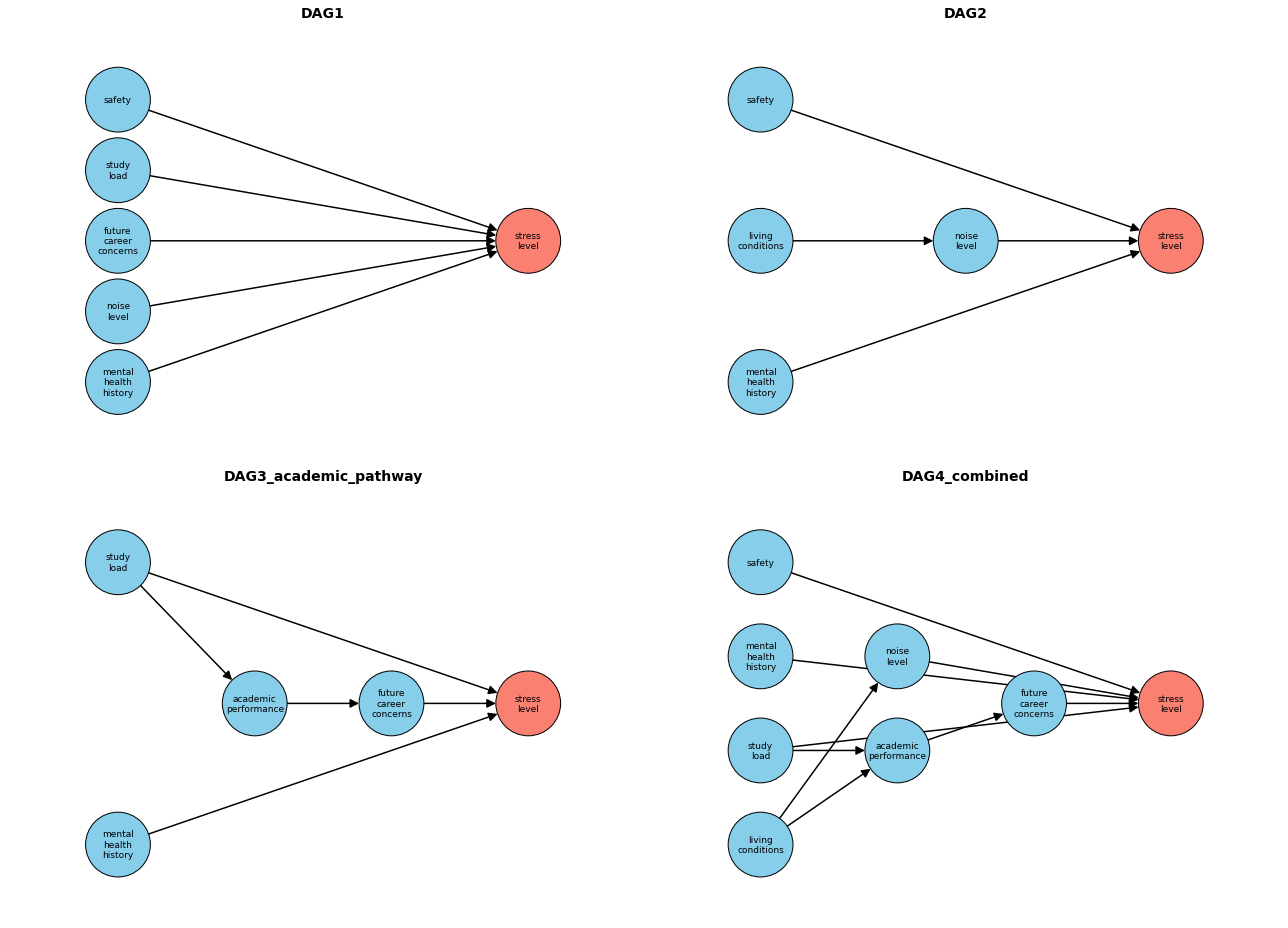

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(18, 13))
for ax, (name, g) in zip(axes.ravel(), graphs.items()):
    # layer = length of longest path from a root node (works in any networkx version)
    for n in nx.topological_sort(g):
        preds = list(g.predecessors(n))
        g.nodes[n]['layer'] = 0 if not preds else max(g.nodes[p]['layer'] for p in preds) + 1
    pos = nx.multipartite_layout(g, subset_key='layer')
    colors = ['salmon' if n == OUTCOME else 'skyblue' for n in g]
    nx.draw_networkx_nodes(g, pos, ax=ax, node_size=4200, node_color=colors, edgecolors='black')
    nx.draw_networkx_labels(g, pos, ax=ax, labels={n: n.replace('_', '\n') for n in g}, font_size=9)
    nx.draw_networkx_edges(g, pos, ax=ax, node_size=4200, arrowstyle='-|>', arrowsize=18, width=1.5)
    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.margins(0.2)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 3. Compare DAGs with BIC

A DAG's likelihood factorises into each node given its parents, so DAG BIC = sum of BIC(node ~ parents).  
BIC = −2·logL + k·ln(n). **Lower is better**; ΔBIC > 10 is very strong evidence for the better DAG.

In [3]:
def node_bic(df, node, parents):
    y = df[node].astype(float)
    X = sm.add_constant(df[parents].astype(float), has_constant='add') if parents \
        else np.ones((len(df), 1))
    return sm.OLS(y, X).fit().bic

def dag_bic(df, g):
    # Nodes in the DAG: scored given their parents.
    # Variables not in this DAG: scored as independent, so every DAG is scored on the same data.
    in_dag = sum(node_bic(df, n, list(g.predecessors(n))) for n in g.nodes)
    not_in_dag = sum(node_bic(df, n, []) for n in all_nodes if n not in g)
    return in_dag + not_in_dag

bic_table = pd.DataFrame({
    'DAG': list(graphs),
    'edges': [g.number_of_edges() for g in graphs.values()],
    'BIC': [dag_bic(data, g) for g in graphs.values()],
}).sort_values('BIC').reset_index(drop=True)
bic_table['delta_BIC'] = bic_table['BIC'] - bic_table['BIC'].min()
print(bic_table.to_string(index=False))

best = bic_table.loc[0, 'DAG']
best_graph = graphs[best]
print('\nBest DAG:', best)
print('Edges:', list(best_graph.edges()))

                  DAG  edges          BIC   delta_BIC
        DAG4_combined      9 24298.884434    0.000000
DAG3_academic_pathway      5 24946.442761  647.558327
                 DAG2      4 25568.815541 1269.931107
                 DAG1      5 25615.237184 1316.352750

Best DAG: DAG4_combined
Edges: [('safety', 'stress_level'), ('mental_health_history', 'stress_level'), ('study_load', 'stress_level'), ('study_load', 'academic_performance'), ('noise_level', 'stress_level'), ('future_career_concerns', 'stress_level'), ('living_conditions', 'noise_level'), ('living_conditions', 'academic_performance'), ('academic_performance', 'future_career_concerns')]


### 4. Is each causal effect identified? (DoWhy)

In [4]:
estimands = {}
for cause in CAUSES:
    if cause not in best_graph or not nx.has_path(best_graph, cause, OUTCOME):
        print(f'\n========== {cause} -> {OUTCOME} ==========')
        print(f'No directed path from {cause} to {OUTCOME} in {best}: '
              'the DAG assumes no causal effect, so there is nothing to identify.')
        continue
    model = CausalModel(data=data, graph=best_graph, treatment=cause, outcome=OUTCOME)
    estimand = model.identify_effect()
    estimands[cause] = (model, estimand)
    print(f'\n========== {cause} -> {OUTCOME} ==========')
    print(estimand)


========== study_load -> stress_level ==========
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
      d                      
─────────────(E[stressₗₑᵥₑₗ])
d[study_load]                
Estimand assumption 1, Unconfoundedness: If U→{study_load} and U→stress_level then P(stress_level|study_load,,U) = P(stress_level|study_load,)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!


========== noise_level -> stress_level ==========
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
      d                                         
─────────────(E[stress_level|living_conditions])
d[noiseₗₑᵥₑₗ]                                   
Estimand assumption 1, Unconfoundedness: If U→{noise_level} and U→stress_level then P(stress_level|noise_level,living_conditions,U) = P(stress_level|noise_level,living

### 5. Causal impact of each cause (DoWhy)

Effect = change in `stress_level` per 1-unit increase in the cause (total effect, backdoor linear regression).

In [5]:
rows = []
for cause, (model, estimand) in estimands.items():
    est = model.estimate_effect(estimand, method_name='backdoor.linear_regression',
                                test_significance=True)
    p = est.test_stat_significance()['p_value']
    rows.append({'cause': cause,
                 'adjustment_set': estimand.get_backdoor_variables(),
                 'causal_effect': round(est.value, 4),
                 'p_value': float(np.ravel(p)[0])})
effects = pd.DataFrame(rows).sort_values('causal_effect', key=abs, ascending=False)
print(effects.to_string(index=False))

                 cause            adjustment_set  causal_effect      p_value
  academic_performance [noise_level, study_load]        -0.1746 1.054092e-01
     living_conditions                        []        -0.1642 8.496613e-12
future_career_concerns    [academic_performance]         0.1465 1.548783e-07
            study_load                        []         0.1451 1.485283e-13
           noise_level       [living_conditions]         0.1226 1.535679e-16


#### Robustness: placebo refuter (effect should drop to ~0)

In [6]:
for cause, (model, estimand) in estimands.items():
    est = model.estimate_effect(estimand, method_name='backdoor.linear_regression')
    ref = model.refute_estimate(estimand, est, method_name='placebo_treatment_refuter',
                                placebo_type='permute', num_simulations=20)
    print(f'{cause:24s} estimate={est.value:.4f}  placebo={ref.new_effect:.4f}')

study_load               estimate=0.1451  placebo=-0.0032
noise_level              estimate=0.1226  placebo=0.0001
living_conditions        estimate=-0.1642  placebo=-0.0073
academic_performance     estimate=-0.1746  placebo=-0.0022
future_career_concerns   estimate=0.1465  placebo=0.0035


---
# Part 1: Oliver (Linear + XGBoost, DML by hand)

**Models:** `LinearRegression` and `XGBRegressor` as nuisance models, in all four pairings (model_y, model_t).
The final stage is a linear regression of the Y residuals on the T residuals, with 5-fold cross-fitting. No EconML.

**Controls:** 8 pre-treatment confounders (mental_health_history, safety, basic_needs, social_support,
teacher_student_relationship, peer_pressure, bullying, extracurricular_activities), plus the DAG4 structure among the causes.
Left out: variables likely *caused by* stress (anxiety_level, depression, headache, blood_pressure, sleep_quality,
breathing_problem, self_esteem).

**Takeaways**
- Every variable DAG4 left out correlates 0.35–0.73 with every cause and 0.44–0.78 with stress, so DAG4's
  "nothing causes study_load / living_conditions" assumption fails.
- The first principal component explains 63% of the variance, so the data is close to a single factor.
- After adjusting, 4 of 5 ATEs are ≈ 0 and their CIs include 0. academic_performance is negative in every spec (−0.04 to −0.09)
  and significant in 3 of 4.
- Linear + Linear (spec C) is the outlier and gives A3-sized effects, because linear models in both stages miss nonlinear
  confounding. Any spec with XGBoost in either stage removes it.
- Best spec: **D (XGBoost for Y, Linear for T)**. r2_y is tied, r2_t is the highest, and it agrees with A and B. All placebos are within ±0.022.

### Finding 1: everything correlates with everything

We overlooked this in A3, but also were mosly focused on a subset of variables to create interpretable DAGs with. But there are many more variables in the set that correlate with stress (or each other) that would be helpful to put into a model.

Many are likely caused by stress, rather than the other way around. All the stuff like blood pessure.

In [7]:
treatments = ["study_load", "living_conditions", "noise_level",
              "academic_performance", "future_career_concerns"]
others = [c for c in df.columns if c not in treatments + ["stress_level"]]

# how strongly each variable you left out relates to each treatment and to stress
corr = df.corr(method="spearman")
print(corr.loc[others, treatments + ["stress_level"]].round(2))

                              study_load  living_conditions  noise_level  \
anxiety_level                       0.63              -0.62         0.64   
self_esteem                        -0.62               0.61        -0.62   
mental_health_history               0.56              -0.54         0.55   
depression                          0.64              -0.59         0.60   
headache                            0.59              -0.59         0.59   
blood_pressure                      0.38              -0.34         0.39   
sleep_quality                      -0.60               0.59        -0.62   
breathing_problem                   0.47              -0.50         0.49   
safety                             -0.54               0.60        -0.58   
basic_needs                        -0.56               0.56        -0.62   
teacher_student_relationship       -0.57               0.60        -0.58   
social_support                     -0.51               0.52        -0.53   
peer_pressur

#### Finding 2: The first is 0.63, basically contributes a lot and our R^2 is expected to be high, very high. This can be a problem for DML because what does the ML even have to learn at this point? Also confounding issues with T and might find low CATE. Like if stress is 63% caused by ___, the control vs treatment won't make a huge difference

In [8]:
import numpy as np
eig = np.linalg.eigvalsh(df.corr(method="spearman"))[::-1]
print((eig / eig.sum())[:3].round(2))  # if the first is ~0.6+, it's essentially one factor

[0.63 0.05 0.03]


### Trial 1: simple linear regression for the outcome variable, XGBoost for the treatment model. Simple linear regression for the residual-on-residual bit.

In [9]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import r2_score
from xgboost import XGBRegressor

Y = df["stress_level"].values

# confounders from the data check (likely stress symptoms excluded)
confounders = ["mental_health_history", "safety", "basic_needs", "social_support",
               "teacher_student_relationship", "peer_pressure", "bullying",
               "extracurricular_activities"]

# DAG4 structure among treatments, plus the new confounders
adj = {
    "study_load": confounders,
    "living_conditions": confounders,
    "noise_level": confounders + ["living_conditions"],
    "academic_performance": confounders + ["living_conditions", "study_load"],
    "future_career_concerns": confounders + ["academic_performance"],
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def dml(Y, T, W):
    # stage 1: predict Y from W (out-of-fold) -> residuals
    y_hat = cross_val_predict(LinearRegression(), W, Y, cv=kf)
    # stage 2: predict T from W (out-of-fold) -> residuals
    t_hat = cross_val_predict(XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.1), W, T, cv=kf)
    y_res, t_res = Y - y_hat, T - t_hat

    # stage 3: residual-on-residual linear regression
    final = LinearRegression().fit(t_res.reshape(-1, 1), y_res)
    theta = final.coef_[0]

    # standard error of the slope
    e = y_res - final.predict(t_res.reshape(-1, 1))
    se = np.sqrt(np.sum(t_res**2 * e**2)) / np.sum(t_res**2)

    return theta, se, r2_score(Y, y_hat), r2_score(T, t_hat)

rng = np.random.default_rng(42)
results = {}
for t, w_cols in adj.items():
    T = df[t].values
    W = df[w_cols].values

    theta, se, r2_y, r2_t = dml(Y, T, W)
    placebo_theta, _, _, _ = dml(Y, rng.permutation(T), W)  # shuffled T should give ~0

    results[t] = {
        "ATE": theta,
        "CI_low": theta - 1.96 * se,
        "CI_high": theta + 1.96 * se,
        "R2_y": r2_y,
        "R2_t": r2_t,
        "placebo_ATE": placebo_theta,
    }

print(pd.DataFrame(results).T.round(3))

                          ATE  CI_low  CI_high   R2_y   R2_t  placebo_ATE
study_load              0.007  -0.038    0.051  0.729  0.370       -0.006
living_conditions       0.017  -0.035    0.068  0.729  0.322        0.001
noise_level             0.022  -0.023    0.067  0.730  0.416       -0.013
academic_performance   -0.042  -0.090    0.007  0.738  0.559        0.011
future_career_concerns -0.027  -0.087    0.033  0.738  0.610       -0.012


### Finding 3: every ATE is close to 0. 
#### Last assignment we said study load, living conditions, noise level, academic performance, and future career concerns affect stress. DML is suggesting otherwise - tuning any of these 5 doesn't move the needle much.
This is because R^2_y is 73% across the board - counfounders are doing a lot of work to explain stress, not much any of these 5 individually do if 73% of stress is already determined by the confounders.

### Test: try XGBoost & XGBoost, XGBoost & Linear, Linear & XGBoost, Linear & Linear

In [10]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import r2_score
from xgboost import XGBRegressor

Y = df["stress_level"].values

# confounders from the data check (likely stress symptoms excluded)
confounders = ["mental_health_history", "safety", "basic_needs", "social_support",
               "teacher_student_relationship", "peer_pressure", "bullying",
               "extracurricular_activities"]

# DAG4 structure among treatments, plus the new confounders
adj = {
    "study_load": confounders,
    "living_conditions": confounders,
    "noise_level": confounders + ["living_conditions"],
    "academic_performance": confounders + ["living_conditions", "study_load"],
    "future_career_concerns": confounders + ["academic_performance"],
}

# our two ML models
models = {
    "Linear": lambda: LinearRegression(),
    "XGB": lambda: XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.1),
}

# (model_y, model_t) pairs -- A is the original run
specs = {
    "A_Linear_XGB": ("Linear", "XGB"),
    "B_XGB_XGB": ("XGB", "XGB"),
    "C_Linear_Linear": ("Linear", "Linear"),
    "D_XGB_Linear": ("XGB", "Linear"),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def dml(Y, T, W, model_y, model_t):
    # stage 1: predict Y from W (out-of-fold) -> residuals
    y_hat = cross_val_predict(models[model_y](), W, Y, cv=kf)
    # stage 2: predict T from W (out-of-fold) -> residuals
    t_hat = cross_val_predict(models[model_t](), W, T, cv=kf)
    y_res, t_res = Y - y_hat, T - t_hat

    # stage 3: residual-on-residual linear regression
    final = LinearRegression().fit(t_res.reshape(-1, 1), y_res)
    theta = final.coef_[0]

    # standard error of the slope
    e = y_res - final.predict(t_res.reshape(-1, 1))
    se = np.sqrt(np.sum(t_res**2 * e**2)) / np.sum(t_res**2)

    return theta, se, r2_score(Y, y_hat), r2_score(T, t_hat)

rows = []
for spec, (my, mt) in specs.items():
    rng = np.random.default_rng(42)  # same placebo shuffle for every spec
    for t, w_cols in adj.items():
        T = df[t].values
        W = df[w_cols].values

        theta, se, r2_y, r2_t = dml(Y, T, W, my, mt)
        placebo_theta, _, _, _ = dml(Y, rng.permutation(T), W, my, mt)  # shuffled T should give ~0

        rows.append({
            "spec": spec,
            "treatment": t,
            "ATE": theta,
            "CI_low": theta - 1.96 * se,
            "CI_high": theta + 1.96 * se,
            "R2_y": r2_y,
            "R2_t": r2_t,
            "placebo_ATE": placebo_theta,
        })

results = pd.DataFrame(rows).set_index(["treatment", "spec"]).sort_index()
print(results.round(3))

# side-by-side ATEs across specs
print(results["ATE"].unstack("spec").round(3))

results.to_csv("../results/dml_results.csv")  # saves everything

                                          ATE  CI_low  CI_high   R2_y   R2_t  \
treatment              spec                                                    
academic_performance   A_Linear_XGB    -0.042  -0.090    0.007  0.738  0.559   
                       B_XGB_XGB       -0.063  -0.114   -0.013  0.731  0.559   
                       C_Linear_Linear -0.089  -0.138   -0.039  0.738  0.584   
                       D_XGB_Linear    -0.054  -0.105   -0.004  0.731  0.584   
future_career_concerns A_Linear_XGB    -0.027  -0.087    0.033  0.738  0.610   
                       B_XGB_XGB       -0.036  -0.092    0.020  0.723  0.610   
                       C_Linear_Linear  0.056   0.000    0.111  0.738  0.659   
                       D_XGB_Linear    -0.033  -0.090    0.025  0.723  0.659   
living_conditions      A_Linear_XGB     0.017  -0.035    0.068  0.729  0.322   
                       B_XGB_XGB       -0.006  -0.059    0.047  0.737  0.322   
                       C_Linear_Linear -

#### XGB for Y and Linear for T wins!!!!!!

#### Best fit, highest T R², catchs non-linear confounding.

#### Once confounders are handled properly, most of the causes we used in A3 have no effect on stress. Academic performance has a small effect (really small). Effects we found in A3 are mostly due to confounders we didn't control for (damn). 

# Get the CATE

In [11]:
# CATE for spec D (XGB for Y, Linear for T): effect allowed to differ by mental_health_history
cate_rows = []
for t, w_cols in adj.items():
    T = df[t].values
    W = df[w_cols].values
    mhh = df["mental_health_history"].values

    # stages 1 and 2: same as spec D
    y_res = Y - cross_val_predict(models["XGB"](), W, Y, cv=kf)
    t_res = T - cross_val_predict(models["Linear"](), W, T, cv=kf)

    # stage 3 with interaction: y_res = θ0·t_res + θ1·(t_res × mhh)
    Z = np.column_stack([t_res, t_res * mhh])
    theta0, theta1 = LinearRegression(fit_intercept=False).fit(Z, y_res).coef_

    cate_rows.append({"treatment": t,
                      "CATE_no_mh_history": theta0,
                      "CATE_mh_history": theta0 + theta1,
                      "difference": theta1})

print(pd.DataFrame(cate_rows).set_index("treatment").round(3))

                        CATE_no_mh_history  CATE_mh_history  difference
treatment                                                              
study_load                           0.062           -0.005      -0.066
living_conditions                    0.028           -0.062      -0.090
noise_level                          0.067           -0.001      -0.068
academic_performance                -0.054           -0.055      -0.001
future_career_concerns              -0.066           -0.008       0.058


---
# Part 2: Minhae (XGBoost + SVR, EconML `LinearDML`)

**Models:** XGBoost for the outcome, SVR (scaled, RBF kernel) for the treatment. She also ran the roles swapped, Linear + Linear DML,
non-causal XGB/SVR "bump" effects, and OLS checks.

**Controls:** W = the A3 adjustment sets (0–2 vars). X (effect modifiers) = safety, mental_health_history.
`LinearDML` adjusts for both, so 2–4 variables in total.

**Takeaways**
- The ATEs are large and mostly significant: study_load +0.12, noise +0.10, career +0.07, living −0.06,
  academic −0.04 (n.s.). That's close to A3.
- The likely reason is that only 2–4 variables are adjusted for. Her own OLS check shows how much this matters: adding just safety +
  mental_health_history cuts study_load from 0.40 to 0.18. Parts 1 and 4 adjust for 8–17 variables, and their effects drop to ≈ 0.
- r2_t is the lowest on the team (0.27–0.36 for three causes), so the treatment model removes little.
- The placebo passes (|ATE| ≤ 0.007, CI covers 0 in 23 of 25 runs). Swapping the model roles changes the ATEs by ≤ 0.01.
- **CATE:** effects are larger for students with a mental health history (e.g. study_load 0.15 vs 0.09).
- Her Linear + Linear DML gives 0.12–0.18, the same pattern as Oliver's spec C.
- The scorecard at the end (`evaluate_model` / `scorecard` / `compare_all`) is the team's tool for comparing models (Q8).

*Edits for this notebook:* the `ADJ` dict is moved above its first use (the original only ran out of order), and debug and duplicate
comparison cells are dropped.

In [ ]:
# !pip install econml xgboost scikit-learn
from econml.dml import LinearDML
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Effect modifiers (X): outcome-only parents in DAG4, so they are safe to use
X_COLS = ['safety', 'mental_health_history']

def make_xgb():   # outcome model
    return XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05,
                        subsample=0.8, n_jobs=-1, random_state=0)

def make_svr():   # treatment model (SVR needs scaled inputs)
    return make_pipeline(StandardScaler(), SVR(kernel='rbf', C=1.0))

In [ ]:
# Adjustment sets from DAG4 (same as your A3 submission)
ADJ = {
    'study_load': [],
    'noise_level': ['living_conditions'],
    'living_conditions': [],
    'academic_performance': ['study_load', 'living_conditions'],
    'future_career_concerns': ['academic_performance'],
}

### 5. Double ML (EconML `LinearDML`) for each cause

For each cause: controls (W) = the adjustment set DoWhy found in A3; effect modifiers (X) = `safety`, `mental_health_history`.

In [ ]:
dml_rows, dml_models = [], {}

for cause, (model, estimand) in estimands.items():
    W_cols = ADJ[cause]  # adjustment set from DoWhy / A3
    Y = data[OUTCOME].values
    T = data[cause].values
    X = data[X_COLS].values
    W = data[W_cols].values if W_cols else None

    est = LinearDML(model_y=make_xgb(), model_t=make_svr(),
                    discrete_treatment=False, cv=5, random_state=0)
    est.fit(Y, T, X=X, W=W)

    ate = float(np.ravel(est.ate(X))[0])
    lo, hi = est.ate_interval(X, alpha=0.05)
    dml_models[cause] = est
    dml_rows.append({'cause': cause, 'adjustment_set': W_cols,
                     'DML_ATE': round(ate, 4),
                     'CI_low': round(float(np.ravel(lo)[0]), 4),
                     'CI_high': round(float(np.ravel(hi)[0]), 4)})

dml_df = pd.DataFrame(dml_rows)
print(dml_df.to_string(index=False))

                 cause                  adjustment_set  DML_ATE  CI_low  CI_high
            study_load                              []   0.1206  0.0765   0.1648
           noise_level             [living_conditions]   0.0975  0.0511   0.1438
     living_conditions                              []  -0.0593 -0.1065  -0.0122
  academic_performance [study_load, living_conditions]  -0.0430 -0.0958   0.0098
future_career_concerns          [academic_performance]   0.0695  0.0087   0.1302


### 5b. CATE: how the effect varies across students

In [ ]:
for cause, est in dml_models.items():
    cate = est.effect(data[X_COLS].values)
    print(f'\n{cause}: mean={cate.mean():.4f}  std={cate.std():.4f}')
    print(pd.Series(cate).groupby(data['mental_health_history'].values).mean().round(4).to_string())


study_load: mean=0.1206  std=0.0338
0    0.0896
1    0.1526

noise_level: mean=0.0975  std=0.0255
0    0.0797
1    0.1158

living_conditions: mean=-0.0593  std=0.0606
0    0.0003
1   -0.1207

academic_performance: mean=-0.0430  std=0.0189
0   -0.0395
1   -0.0465

future_career_concerns: mean=0.0695  std=0.0566
0    0.0368
1    0.1031


### 6. Non-causal ML baselines

Predict `stress_level` from *all* other variables (no DAG, no adjustment sets), then measure how the prediction changes when a cause is raised by 1 unit.

In [ ]:
FEATURES = [c for c in data.columns if c != OUTCOME]

def naive_effect(make_model, cause):
    m = make_model().fit(data[FEATURES], data[OUTCOME])
    bumped = data[FEATURES].copy()
    bumped[cause] += 1
    return float(np.mean(m.predict(bumped) - m.predict(data[FEATURES])))

naive = pd.DataFrame({
    'cause': CAUSES,
    'XGB_naive': [round(naive_effect(make_xgb, c), 4) for c in CAUSES],
    'SVR_naive': [round(naive_effect(make_svr, c), 4) for c in CAUSES],
})
naive

,cause,XGB_naive,SVR_naive
0,study_load,0.0073,0.0515
1,noise_level,0.1153,0.0417
2,living_conditions,-0.0827,-0.0311
3,academic_performance,-0.0483,-0.0311
4,future_career_concerns,0.1354,0.0991


### OLS check: how much do two extra controls change the estimate?

In [ ]:
rows = []
for cause in CAUSES:
    for label, cols in [('adj only', ADJ[cause]),
                        ('adj + safety/mh_history', ADJ[cause] + X_COLS)]:
        Xm = sm.add_constant(data[[cause] + cols].astype(float))
        m = sm.OLS(data[OUTCOME].astype(float), Xm).fit()
        rows.append({'cause': cause, 'controls': label,
                     'effect': round(m.params[cause], 4),
                     'p_value': m.pvalues[cause]})

ols_check = pd.DataFrame(rows)
print(ols_check.to_string(index=False))

                 cause                controls  effect       p_value
            study_load                adj only  0.3960 8.445394e-125
            study_load adj + safety/mh_history  0.1767  1.476943e-35
           noise_level                adj only  0.3113  1.495034e-88
           noise_level adj + safety/mh_history  0.1819  1.350006e-38
     living_conditions                adj only -0.4271 1.325429e-100
     living_conditions adj + safety/mh_history -0.1260  6.468157e-13
  academic_performance                adj only -0.2624  5.336271e-76
  academic_performance adj + safety/mh_history -0.1645  6.494137e-31
future_career_concerns                adj only  0.2555  6.249236e-79
future_career_concerns adj + safety/mh_history  0.1626  1.594715e-31


### Linear + Linear DML (compare with Oliver's spec C)

In [ ]:
from sklearn.linear_model import LinearRegression

lin_rows = []
for cause in CAUSES:
    W_cols = ADJ[cause]
    est = LinearDML(model_y=LinearRegression(), model_t=LinearRegression(),
                    discrete_treatment=False, cv=5, random_state=0)
    est.fit(data[OUTCOME].values, data[cause].values, X=data[X_COLS].values,
            W=data[W_cols].values if W_cols else None)
    lin_rows.append({'cause': cause,
                     'DML_linear': round(float(np.ravel(est.ate(data[X_COLS].values))[0]), 4)})
pd.DataFrame(lin_rows)

,cause,DML_linear
0,study_load,0.1700
1,noise_level,0.1754
2,living_conditions,-0.1246
3,academic_performance,-0.1620
4,future_career_concerns,0.1536


### Nuisance model fit (cross-validated R²)

In [ ]:
from sklearn.model_selection import cross_val_score

for cause in CAUSES:
    cols = ADJ[cause] + X_COLS
    r2y = cross_val_score(make_xgb(), data[cols], data[OUTCOME], cv=5, scoring='r2').mean()
    r2t = cross_val_score(make_svr(), data[cols], data[cause], cv=5, scoring='r2').mean()
    print(f'{cause:24s} R2 outcome(XGB)={r2y:.3f}  R2 treatment(SVR)={r2t:.3f}')

study_load               R2 outcome(XGB)=0.653  R2 treatment(SVR)=0.315
noise_level              R2 outcome(XGB)=0.693  R2 treatment(SVR)=0.362
living_conditions        R2 outcome(XGB)=0.653  R2 treatment(SVR)=0.274
academic_performance     R2 outcome(XGB)=0.721  R2 treatment(SVR)=0.549
future_career_concerns   R2 outcome(XGB)=0.740  R2 treatment(SVR)=0.631


### Placebo: shuffled cause, 5 repeats

In [ ]:
rng2 = np.random.default_rng(0)
REPS = 5
plc = []
for cause in CAUSES:
    W_cols = ADJ[cause]
    ates, covers = [], []
    for r in range(REPS):
        T_fake = rng2.permutation(data[cause].values)
        est = LinearDML(model_y=make_xgb(), model_t=make_svr(),
                        discrete_treatment=False, cv=5, random_state=0)
        est.fit(data[OUTCOME].values, T_fake, X=data[X_COLS].values,
                W=data[W_cols].values if W_cols else None)
        ate = float(np.ravel(est.ate(data[X_COLS].values))[0])
        lo, hi = est.ate_interval(data[X_COLS].values, alpha=0.05)
        ates.append(ate)
        covers.append(float(np.ravel(lo)[0]) <= 0 <= float(np.ravel(hi)[0]))
    plc.append({'cause': cause,
                'placebo_ATE_mean': round(np.mean(ates), 4),
                'CI_includes_0': f'{sum(covers)}/{REPS}'})
pd.DataFrame(plc)

,cause,placebo_ATE_mean,CI_includes_0
0,study_load,0.0030,5/5
1,noise_level,-0.0068,4/5
2,living_conditions,0.0054,5/5
3,academic_performance,0.0029,4/5
4,future_career_concerns,0.0030,5/5


### Swapped roles: SVR for the outcome, XGBoost for the treatment

In [ ]:
sw = []
for cause in CAUSES:
    W_cols = ADJ[cause]
    est = LinearDML(model_y=make_svr(), model_t=make_xgb(),
                    discrete_treatment=False, cv=5, random_state=0)
    est.fit(data[OUTCOME].values, data[cause].values, X=data[X_COLS].values,
            W=data[W_cols].values if W_cols else None)
    sw.append({'cause': cause,
               'DML_swapped': round(float(np.ravel(est.ate(data[X_COLS].values))[0]), 4)})
pd.DataFrame(sw)

,cause,DML_swapped
0,study_load,0.1297
1,noise_level,0.0891
2,living_conditions,-0.0670
3,academic_performance,-0.0497
4,future_career_concerns,0.0613


### Final table

In [ ]:
ols_adj = (ols_check[ols_check.controls == 'adj only'][['cause', 'effect']]
           .rename(columns={'effect': 'OLS_adj_only'}))
ols_adjx = (ols_check[ols_check.controls == 'adj + safety/mh_history'][['cause', 'effect']]
            .rename(columns={'effect': 'OLS_adj_plus_X'}))

final = (ols_adj.merge(ols_adjx, on='cause')
         .merge(dml_df[['cause', 'DML_ATE', 'CI_low', 'CI_high']], on='cause')
         .merge(pd.DataFrame(sw), on='cause')
         .merge(naive, on='cause')
         .merge(pd.DataFrame(plc)[['cause', 'placebo_ATE_mean', 'CI_includes_0']], on='cause')
         .rename(columns={'CI_includes_0': 'placebo_CI_includes_0'}))

col_order = ['cause',
             'DML_ATE', 'CI_low', 'CI_high',        # main estimate + uncertainty
             'DML_swapped',                         # robustness to model choice
             'placebo_ATE_mean', 'placebo_CI_includes_0',  # validation
             'OLS_adj_plus_X',                      # fair linear baseline
             'OLS_adj_only',                        # weaker linear baseline
             'XGB_naive', 'SVR_naive']              # non-causal ML

final = final[col_order]
final = final.reindex(final['DML_ATE'].abs().sort_values(ascending=False).index).reset_index(drop=True)
final

,cause,DML_ATE,CI_low,CI_high,DML_swapped,placebo_ATE_mean,placebo_CI_includes_0,OLS_adj_plus_X,OLS_adj_only,XGB_naive,SVR_naive
0,study_load,0.1206,0.0765,0.1648,0.1297,0.0030,5/5,0.1767,0.3960,0.0073,0.0515
1,noise_level,0.0975,0.0511,0.1438,0.0891,-0.0068,4/5,0.1819,0.3113,0.1153,0.0417
2,future_career_concerns,0.0695,0.0087,0.1302,0.0613,0.0030,5/5,0.1626,0.2555,0.1354,0.0991
3,living_conditions,-0.0593,-0.1065,-0.0122,-0.0670,0.0054,5/5,-0.1260,-0.4271,-0.0827,-0.0311
4,academic_performance,-0.0430,-0.0958,0.0098,-0.0497,0.0029,4/5,-0.1645,-0.2624,-0.0483,-0.0311


### Scorecard for comparing models across the team (Q8)

In [ ]:
from sklearn.model_selection import cross_val_score

def _fit_dml(make_y, make_t, T, W_cols):
    X = data[X_COLS].values
    est = LinearDML(model_y=make_y(), model_t=make_t(),
                    discrete_treatment=False, cv=5, random_state=0)
    est.fit(data[OUTCOME].values, T, X=X,
            W=data[W_cols].values if W_cols else None)
    ate = float(np.ravel(est.ate(X))[0])
    lo, hi = est.ate_interval(X, alpha=0.05)
    return ate, float(np.ravel(lo)[0]), float(np.ravel(hi)[0])


def evaluate_model(name, make_y, make_t, reps=3, seed=0):
    """Runs DML for all causes + the validation checks. Returns one row per cause."""
    rng = np.random.default_rng(seed)
    rows = []
    for cause in CAUSES:
        W_cols, T = ADJ[cause], data[cause].values
        ate, lo, hi = _fit_dml(make_y, make_t, T, W_cols)
        ate_swap, _, _ = _fit_dml(make_t, make_y, T, W_cols)            # roles swapped
        plc = [_fit_dml(make_y, make_t, rng.permutation(T), W_cols)     # placebo (shuffled cause)
               for _ in range(reps)]
        cols = W_cols + X_COLS
        r2_y = cross_val_score(make_y(), data[cols], data[OUTCOME], cv=5, scoring='r2').mean()
        r2_t = cross_val_score(make_t(), data[cols], data[cause], cv=5, scoring='r2').mean()
        rows.append({'model': name, 'cause': cause,
                     'ATE': ate, 'CI_low': lo, 'CI_high': hi,
                     'swap_diff': abs(ate - ate_swap),
                     'placebo_abs': np.mean([abs(p[0]) for p in plc]),
                     'placebo_cover': np.mean([p[1] <= 0 <= p[2] for p in plc]),
                     'r2_y': r2_y, 'r2_t': r2_t})
    return pd.DataFrame(rows)


def scorecard(detail):
    """detail = per-cause rows from one or MANY models (concatenated)."""
    df = detail.copy()
    df['ci_width'] = df['CI_high'] - df['CI_low']
    consensus = df.groupby('cause')['ATE'].median()          # needs 3+ models to mean much
    df['dev_from_consensus'] = (df['ATE'] - df['cause'].map(consensus)).abs()

    sc = df.groupby('model').agg(placebo_abs=('placebo_abs', 'mean'),
                                 placebo_cover=('placebo_cover', 'mean'),
                                 swap_diff=('swap_diff', 'mean'),
                                 r2_y=('r2_y', 'mean'),
                                 r2_t=('r2_t', 'mean'),            # shown, not ranked
                                 ci_width=('ci_width', 'mean'),
                                 dev_from_consensus=('dev_from_consensus', 'mean'))
    ranks = pd.DataFrame({
        'placebo_abs':        sc['placebo_abs'].rank(),
        'placebo_cover':      (sc['placebo_cover'] - 0.95).abs().rank(),
        'swap_diff':          sc['swap_diff'].rank(),
        'r2_y':               sc['r2_y'].rank(ascending=False),
        'ci_width':           sc['ci_width'].rank(),
        'dev_from_consensus': sc['dev_from_consensus'].rank()})
    sc['avg_rank'] = ranks.mean(axis=1)                      # lower = better
    sc['placebo_ok'] = sc['placebo_cover'] >= 0.8            # screening: drop models that fail
    return sc.sort_values(['placebo_ok', 'avg_rank'], ascending=[False, True]).round(4)

import glob, os

def run_my_models(MODELS, who):
    """STEP 1 (everyone): evaluates your models and saves results_<who>.csv"""
    detail = pd.concat([evaluate_model(n, my, mt) for n, (my, mt) in MODELS.items()],
                       ignore_index=True)
    detail.to_csv(f'results_{who}.csv', index=False)
    print(f'Saved results_{who}.csv. Send this file to the group.')

def compare_all(folder='.'):
    """STEP 2 (one person): put everyone's CSVs in one folder, then run this."""
    files = glob.glob(os.path.join(folder, 'results_*.csv'))
    detail_all = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    board = scorecard(detail_all)
    show = board[['placebo_ok', 'swap_diff', 'r2_y', 'ci_width', 'dev_from_consensus', 'avg_rank']]
    print(show.to_string())
    passed = board[board['placebo_ok']]
    if len(board) < 3:
        print('\nNote: need 3+ models for the comparison to mean much.')
    if len(passed):
        print(f'\nBest model: {passed.index[0]}')
    else:
        print('\nNo model passed the placebo check.')
    return board

MODELS = {
    'XGB+SVR': (make_xgb, make_svr),     # put your own models in 
}
run_my_models(MODELS, 'minhae') # put your own name in

---
# Part 3: Camille (MLP + LightGBM, `LinearDML` and `CausalForestDML`) + Q6 non-causal models

Her code was four `.py` modules plus a notebook. It's inlined and trimmed here: DAG4 is reused from Part 0, and the file loaders,
the unused `threshold` argument and the `__main__` blocks are removed. The logic is unchanged.

**Models:** MLP (scaled) and LightGBM, each used as *both* model_y and model_t, under `LinearDML` and `CausalForestDML`.
That's four fits per cause.

**Controls (X):** DAG4 nodes that aren't the cause, the outcome, or a descendant of the cause (3–6 vars).

**DML takeaways**
- The effects are small: all within ±0.08.
- Signs are consistent across the four fits: study_load and noise go up, living and academic go down, career is ≈ 0.
- With `LinearDML`, study_load (+0.05–0.06) and academic_performance (−0.06 to −0.07) are significant under both learners.
  With `CausalForestDML` nothing is significant, because its CIs are 2–3× wider.
- Her results sit between Minhae's and Oliver's: she adjusts for more variables than Minhae and fewer than Oliver, and her effect sizes fall in between.

**Q6 (non-causal) takeaways**
- LightGBM, RF and MLP are fit on all 20 predictors. The "effect" is the average change in predicted stress when a cause goes up 1 unit.
- These are the best predictors (R² up to 0.80), but the effects are ≈ 0 (0.001–0.042) and 12 of 15 aren't significant. Only academic_performance is
  negative every time.
- The reason: the models condition on variables downstream of stress (anxiety, depression, headache, …), which absorb the variance.
- Predictive accuracy and causal validity rank the models in opposite orders.
- Note: the table she shared with the group was this Q6 table, not her DML results. In that table the RF noise_level row says
  sig = yes, but its CI (−0.017, 0.018) includes 0. The code's own rule labels it "no", so a fresh run is correct.

In [ ]:
# Camille's dag.py, reduced to the one helper she uses. DAG4 = best_graph from Part 0.
def covariates_for(treatment):
    """DAG4 nodes that are not the treatment, the outcome, or a descendant of the treatment.

    Descendants are excluded because conditioning on a variable caused by the
    treatment either blocks part of the effect (mediator) or opens a spurious
    path (collider).
    """
    excluded = {treatment, OUTCOME} | nx.descendants(best_graph, treatment)
    return sorted(n for n in best_graph.nodes if n not in excluded)

for t in TREATMENTS:
    print(f"{t:<24} X = {covariates_for(t)}")

study_load               X = ['living_conditions', 'mental_health_history', 'noise_level', 'safety']
noise_level              X = ['academic_performance', 'future_career_concerns', 'living_conditions', 'mental_health_history', 'safety', 'study_load']
living_conditions        X = ['mental_health_history', 'safety', 'study_load']
academic_performance     X = ['living_conditions', 'mental_health_history', 'noise_level', 'safety', 'study_load']
future_career_concerns   X = ['academic_performance', 'living_conditions', 'mental_health_history', 'noise_level', 'safety', 'study_load']


In [ ]:
# Camille's nuisance.py: the two nuisance learners
from lightgbm import LGBMRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def make_mlp(seed=0):
    # MLPs train badly on unscaled inputs (our columns range from 0-5 up to 0-30)
    return make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            alpha=1e-2,                   # L2 penalty; n is only 1,100
            max_iter=1000,
            early_stopping=True,
            random_state=seed,
        ),
    )

def make_lgbm(seed=0):
    # Small, shallow trees: with 1,100 rows a big model just memorises noise
    return LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=8,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=seed,
        n_jobs=1,        # single thread -> deterministic results
        verbose=-1,
    )

In [ ]:
# Camille's pipeline.py: LinearDML and CausalForestDML x (MLP, LightGBM) for every cause
from econml.dml import CausalForestDML, LinearDML
from sklearn.model_selection import KFold

NUISANCE = {"MLP": make_mlp, "LightGBM": make_lgbm}
ALPHA = 0.05  # -> 95% confidence intervals

def _make_estimator(kind, factory, seed):
    common = dict(
        model_y=factory(seed),
        model_t=factory(seed),
        discrete_treatment=False,
        cv=KFold(n_splits=5, shuffle=True, random_state=seed),
        random_state=seed,
    )
    if kind == "LinearDML":
        return LinearDML(**common)
    return CausalForestDML(n_estimators=200, min_samples_leaf=10, n_jobs=1, **common)

def run_pipeline(df, seed=42):
    """One row per treatment x estimator x nuisance learner: ATE, SE, 95% CI."""
    np.random.seed(seed)
    rows = []
    for t in TREATMENTS:
        X = df[covariates_for(t)].to_numpy(dtype=float)
        for kind in ("LinearDML", "CausalForestDML"):
            for nuis in NUISANCE:
                est = _make_estimator(kind, NUISANCE[nuis], seed)
                est.fit(df[OUTCOME].to_numpy(dtype=float), df[t].to_numpy(dtype=float), X=X)
                inf = est.ate_inference(X)
                lo, hi = inf.conf_int_mean(alpha=ALPHA)
                rows.append({
                    "treatment": t, "estimator": kind, "nuisance": nuis,
                    "ate": float(np.squeeze(inf.mean_point)),
                    "se": float(np.squeeze(inf.stderr_mean)),
                    "ci_low": float(np.squeeze(lo)),
                    "ci_high": float(np.squeeze(hi)),
                })
    out = pd.DataFrame(rows)
    out["significant"] = (out.ci_low > 0) | (out.ci_high < 0)
    return out

def plot_ates(res):
    """Forest plot: ATE and 95% CI per treatment, one panel per estimator."""
    kinds = list(res.estimator.unique())
    fig, axes = plt.subplots(1, len(kinds), figsize=(11, 4), sharey=True, sharex=True)
    colors = {"MLP": "#1f77b4", "LightGBM": "#ff7f0e"}
    treatments = list(res.treatment.unique())
    for ax, kind in zip(np.atleast_1d(axes), kinds):
        for j, nuis in enumerate(NUISANCE):
            d = res[(res.estimator == kind) & (res.nuisance == nuis)].set_index("treatment").loc[treatments]
            y = np.arange(len(treatments)) + (j - 0.5) * 0.25
            ax.errorbar(d.ate, y, xerr=[d.ate - d.ci_low, d.ci_high - d.ate],
                        fmt="o", color=colors[nuis], capsize=3, label=nuis)
        ax.axvline(0, color="grey", lw=1, ls="--")
        ax.set_yticks(range(len(treatments)), treatments)
        ax.set_title(kind)
        ax.set_xlabel("ATE on stress_level (95% CI)")
    np.atleast_1d(axes)[0].invert_yaxis()
    np.atleast_1d(axes)[-1].legend(title="nuisance learner")
    fig.tight_layout()
    return fig

In [ ]:
res = run_pipeline(df, seed=42)
res.round(3)

,treatment,estimator,nuisance,ate,se,ci_low,ci_high,significant
0,study_load,LinearDML,MLP,0.053,0.024,0.006,0.100,True
1,study_load,LinearDML,LightGBM,0.058,0.025,0.010,0.106,True
2,study_load,CausalForestDML,MLP,0.056,0.057,-0.055,0.168,False
3,study_load,CausalForestDML,LightGBM,0.063,0.062,-0.059,0.185,False
4,noise_level,LinearDML,MLP,0.065,0.024,0.017,0.113,True
5,noise_level,LinearDML,LightGBM,0.032,0.025,-0.017,0.081,False
6,noise_level,CausalForestDML,MLP,0.070,0.052,-0.033,0.173,False
7,noise_level,CausalForestDML,LightGBM,0.043,0.050,-0.055,0.141,False
8,living_conditions,LinearDML,MLP,-0.054,0.027,-0.107,-0.000,True
9,living_conditions,LinearDML,LightGBM,-0.034,0.026,-0.086,0.017,False


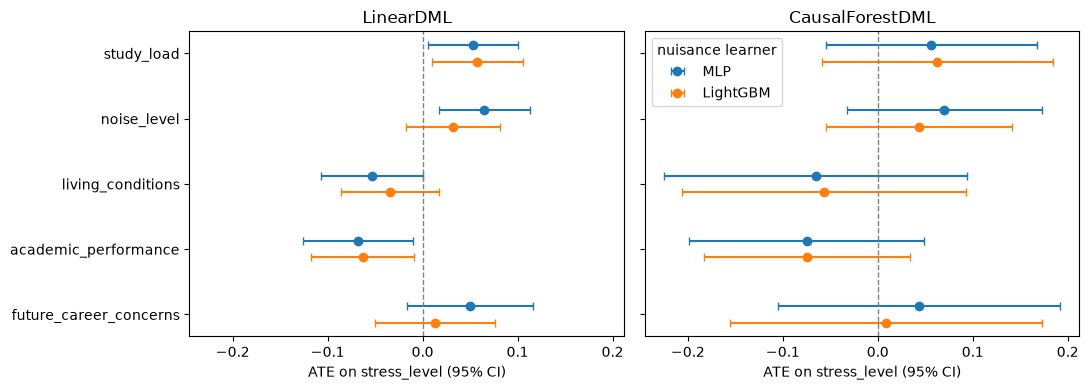

In [ ]:
plot_ates(res);

### Q6: non-causal ML models used to "estimate" causal impacts

In [ ]:
# Camille's q6_noncausal.py. A predictive model has no notion of confounding, mediators or colliders.
# "Effect" = average predicted change in stress when a cause goes up 1 unit (partial-dependence contrast).
# It LOOKS like an ATE and is not one.
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

Q6_SEED = 42

def make_model(name, seed=Q6_SEED):
    if name == "LightGBM":
        return LGBMRegressor(random_state=seed, verbose=-1, n_jobs=1)
    if name == "RandomForest":
        return RandomForestRegressor(n_estimators=300, random_state=seed, n_jobs=-1)
    if name == "MLP":
        return make_pipeline(StandardScaler(),
                             MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=600, random_state=seed))
    raise ValueError(name)

def pd_effect(model, X, treatment, delta=1.0):
    """Average predicted change in outcome from a +1 unit shift in `treatment`."""
    Xb = X.copy()
    Xb[treatment] = Xb[treatment] + delta
    return float(np.mean(model.predict(Xb) - model.predict(X)))

def run_q6(df, models=("LightGBM", "RandomForest", "MLP"), n_boot=200, seed=Q6_SEED):
    rng = np.random.default_rng(seed)
    X, y = df.drop(columns=OUTCOME), df[OUTCOME]
    rows = []
    for name in models:
        # 1. predictive quality - what a non-causal model is actually good at
        r2 = cross_val_score(make_model(name), X, y,
                             cv=KFold(5, shuffle=True, random_state=seed), scoring="r2").mean()
        # 2. point estimates: ONE fit, all treatments
        fitted = make_model(name).fit(X, y)
        point = {t: pd_effect(fitted, X, t) for t in TREATMENTS}
        # 3. bootstrap: ONE refit per resample, all treatments from it
        boots = {t: [] for t in TREATMENTS}
        for _ in range(n_boot):
            idx = rng.integers(0, len(df), len(df))
            m = make_model(name).fit(X.iloc[idx], y.iloc[idx])
            for t in TREATMENTS:
                boots[t].append(pd_effect(m, X.iloc[idx], t))
        # 4. placebo: permute each treatment, refit, re-measure
        placebo = {}
        for t in TREATMENTS:
            Xp = X.copy()
            Xp[t] = rng.permutation(Xp[t].values)
            placebo[t] = pd_effect(make_model(name).fit(Xp, y), Xp, t)
        for t in TREATMENTS:
            lo, hi = np.percentile(boots[t], [2.5, 97.5])
            rows.append({"model": name, "cause": t, "effect": round(point[t], 5),
                         "CI_low": round(lo, 5), "CI_high": round(hi, 5),
                         "sig": "yes" if lo * hi > 0 else "no",
                         "placebo_abs": round(abs(placebo[t]), 5),
                         "r2_outcome": round(r2, 5)})
    return pd.DataFrame(rows)

q6 = run_q6(df, n_boot=50)   # 50 for a fast draft (~2 min); use 200 for the final
q6.to_csv("../results/q6_noncausal.csv", index=False)
q6

**Camille's saved Q6 results** (from her run with the code above; RF noise_level corrected to "no" because its CI includes 0):

| model | cause | effect | CI_low | CI_high | sig | placebo_abs | r2 |
|---|---|---|---|---|---|---|---|
| LightGBM | study_load | 0.00291 | −0.02654 | 0.03972 | no | 0.00057 | 0.785 |
| LightGBM | noise_level | 0.01542 | −0.01602 | 0.06231 | no | 0.00325 | 0.785 |
| LightGBM | living_conditions | 0.00715 | −0.04074 | 0.04026 | no | 0.00418 | 0.785 |
| LightGBM | academic_performance | −0.04238 | −0.07087 | 0.00370 | no | 0.00120 | 0.785 |
| LightGBM | future_career_concerns | −0.00165 | −0.02912 | 0.05404 | no | 0.00346 | 0.785 |
| RandomForest | study_load | 0.00281 | −0.00641 | 0.01293 | no | 0.00084 | 0.802 |
| RandomForest | noise_level | −0.00100 | −0.01706 | 0.01797 | no | 0.00183 | 0.802 |
| RandomForest | living_conditions | −0.00304 | −0.03341 | 0.01359 | no | 0.00068 | 0.802 |
| RandomForest | academic_performance | −0.03005 | −0.09047 | −0.00236 | yes | 0.00071 | 0.802 |
| RandomForest | future_career_concerns | −0.00323 | −0.01095 | 0.02885 | no | 0.00081 | 0.802 |
| MLP | study_load | 0.02021 | 0.00470 | 0.04102 | yes | 0.00310 | 0.688 |
| MLP | noise_level | 0.00639 | −0.01115 | 0.03087 | no | 0.01644 | 0.688 |
| MLP | living_conditions | 0.02623 | −0.00020 | 0.04606 | no | 0.00382 | 0.688 |
| MLP | academic_performance | −0.01403 | −0.02981 | −0.00577 | yes | 0.00773 | 0.688 |
| MLP | future_career_concerns | 0.00918 | −0.02795 | 0.03468 | no | 0.00514 | 0.688 |

With the correction, 3 of 15 are significant: RF academic_performance, MLP study_load and MLP academic_performance.

---
# Part 4: Sabayna (Random Forest + ElasticNet, `LinearDML`)

**Models:** Random Forest for the outcome, ElasticNetCV (scaled) for the treatment, 5-fold cross-fitting.
**Controls:** W = DAG4 adjustment sets. X = the 15 predictors that aren't one of the five causes, which includes the stress symptoms
(anxiety, depression, headache, blood_pressure, sleep_quality, breathing_problem, self_esteem). `LinearDML` adjusts for both.
**Validation:** Minhae's group evaluation code (swap test, placebo with 3 repeats, cross-validated R²).

**Takeaways**
- Nothing is significant: all five CIs include 0. academic_performance (−0.031) and noise_level (+0.020) come closest.
- Effects are 4–10× smaller than A3.
- noise_level's placebo coverage of 0.67 means 1 of only 3 placebo runs had a CI excluding 0. With 3 repeats that's weak evidence
  of a problem, not a failure.
- Swapping the model roles barely matters (≤ 0.004). r2_y ≈ 0.79 is the highest on the team, partly because X includes the stress
  symptoms, which are close to stress itself.

*Edits for this notebook:* her variables are renamed (`sab_data`, `SAB_X_COLS`, `sab_*` functions) so they don't overwrite
Minhae's `data` / `X_COLS` / `evaluate_model`. The evaluation functions are hers (a copy of Minhae's), unchanged.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from econml.dml import LinearDML

sab_data = df  # full dataset (Minhae's `data` only has the 8 DAG4 columns)

# Adjustment sets from DAG4 (Assignment 3)
SAB_ADJ = {'study_load': [], 'living_conditions': [],
           'noise_level': ['living_conditions'],
           'academic_performance': ['living_conditions','study_load'],
           'future_career_concerns': ['academic_performance']}

# X = every predictor that is not one of the 5 causes (15 columns)
SAB_X_COLS = [c for c in sab_data.columns if c != OUTCOME and c not in CAUSES]
print(len(SAB_X_COLS), 'X columns:', SAB_X_COLS)

15 X columns: ['anxiety_level', 'self_esteem', 'mental_health_history', 'depression', 'headache', 'blood_pressure', 'sleep_quality', 'breathing_problem', 'safety', 'basic_needs', 'teacher_student_relationship', 'social_support', 'peer_pressure', 'extracurricular_activities', 'bullying']


### Her two models

In [ ]:
def make_rf():      # outcome model
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                                 n_jobs=-1, random_state=0)

def make_enet():    # treatment model
    return make_pipeline(StandardScaler(),
                         ElasticNetCV(l1_ratio=[.1,.5,.9,1], cv=5, random_state=0, max_iter=5000))

### Group evaluation code
DML fit, swap test, placebo test, and cross-validated R² of both nuisance models.

In [ ]:
def sab_fit_dml(make_y, make_t, T, W_cols):
    X = sab_data[SAB_X_COLS].values
    est = LinearDML(model_y=make_y(), model_t=make_t(),
                    discrete_treatment=False, cv=5, random_state=0)
    est.fit(sab_data[OUTCOME].values, T, X=X,
            W=sab_data[W_cols].values if W_cols else None)
    ate = float(np.ravel(est.ate(X))[0])
    lo, hi = est.ate_interval(X, alpha=0.05)
    return ate, float(np.ravel(lo)[0]), float(np.ravel(hi)[0])

def sab_evaluate_model(name, make_y, make_t, reps=3, seed=0):
    rng = np.random.default_rng(seed); rows = []
    for cause in CAUSES:
        W_cols, T = SAB_ADJ[cause], sab_data[cause].values
        ate, lo, hi = sab_fit_dml(make_y, make_t, T, W_cols)
        ate_swap, _, _ = sab_fit_dml(make_t, make_y, T, W_cols)                       # roles swapped
        plc = [sab_fit_dml(make_y, make_t, rng.permutation(T), W_cols) for _ in range(reps)]  # placebo
        cols = W_cols + SAB_X_COLS
        r2_y = cross_val_score(make_y(), sab_data[cols], sab_data[OUTCOME], cv=5, scoring='r2').mean()
        r2_t = cross_val_score(make_t(), sab_data[cols], sab_data[cause], cv=5, scoring='r2').mean()
        rows.append({'model': name, 'cause': cause, 'ATE': ate, 'CI_low': lo, 'CI_high': hi,
                     'swap_diff': abs(ate-ate_swap),
                     'placebo_abs': np.mean([abs(p[0]) for p in plc]),
                     'placebo_cover': np.mean([p[1] <= 0 <= p[2] for p in plc]),
                     'r2_y': r2_y, 'r2_t': r2_t})
        print('done:', cause, flush=True)
    return pd.DataFrame(rows)

### Run it

In [ ]:
sab_results = sab_evaluate_model('RF+ENet', make_rf, make_enet)
sab_results.to_csv('../results/results_sabayna.csv', index=False)
sab_results.round(4)

---
# Part 5: Team comparison and answers (Q5–Q10)

### ATE per cause (bold = 95% CI excludes 0)

| cause | A3 DoWhy | Minhae XGB+SVR | Camille LinearDML (MLP / LGBM) | Oliver D (XGB+Lin) | Sabayna RF+ENet |
|---|---|---|---|---|---|
| study_load | **+0.145** | **+0.121** | **+0.053** / **+0.058** | +0.027 | +0.014 |
| noise_level | **+0.123** | **+0.097** | **+0.065** / +0.032 | +0.031 | +0.020 |
| living_conditions | **−0.164** | **−0.059** | **−0.054** / −0.034 | −0.012 | +0.025 |
| academic_performance | **−0.165** | −0.043 | **−0.068** / **−0.063** | **−0.054** | −0.031 |
| future_career_concerns | **+0.147** | **+0.069** | +0.050 / +0.014 | −0.033 | −0.040 |
| **variables adjusted for** | 0–2 | 2–4 | 3–6 | 8–10 | 15–17 |

### Main finding
**The more confounders we adjust for, the smaller the effects get.** The table is ordered by how many variables each
analysis controls for, and the effects shrink left to right, from 0.12–0.16 in A3 to ≈ 0 in Oliver's and Sabayna's runs. The large
A3 effects were mostly confounding. academic_performance is the only cause that stays negative in every analysis (≈ −0.03 to −0.07).

### Q5: CATE
Minhae's CATE by mental_health_history shows effects about 1.5–2× larger for students with a mental health history. Camille's
`CausalForestDML` gives CATEs too, but with wide CIs. Oliver's DML gives ATEs only.

### Q6: Non-causal models
Camille's LightGBM / RF / MLP (Part 3) and Minhae's XGB/SVR bump effects (Part 2) predict stress best (R² up to 0.80) but aren't causal
estimates, because they condition on variables caused by stress.

### Q7: Validation, and why we used it
- **Placebo** (shuffled cause → ATE should be ≈ 0): passes everywhere. The one borderline case is Sabayna's noise_level (1 of 3 runs).
- **Model swap** (does the answer depend on which model plays which role?): Minhae ≤ 0.01, Sabayna ≤ 0.004, and Oliver's four specs agree
  except the all-linear one.
- **Nuisance R²** (how much confounding each stage removes).
- **Agreement across the team.**

Why: with observational data there's no true effect to compare against, so we check whether the *method* behaves correctly.

### Q8: Winner
Team pick: **Sabayna's RF + ElasticNet**. It has the highest r2_y (0.79), stable model swaps, and agrees with Oliver's results.
Caveat: her X includes the stress symptoms, which inflates r2_y. Oliver's spec D gets the same answer without them.

### Q9: Summary
Once confounding is handled, study load, noise, housing and career concerns have no detectable effect on stress. Academic performance
has a small protective effect (≈ −0.04 per unit on a 0–2 scale). Limitation: one factor explains 63% of the variance, and the dataset
may be synthetic.

### Q10: Meta-learners or DML?
**DML.** Our causes are 0–5 scales. Meta-learners (S/T/X) are built for binary treatments, so we'd have to cut each scale into two
groups and lose information. DML handles continuous treatments directly, and its residualizing step caught nonlinear confounding
that plain linear adjustment missed (Oliver's spec C vs A/B/D, Minhae's Linear + Linear run).